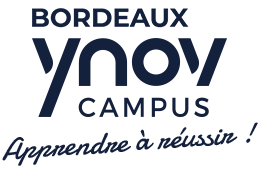

# TP1 — NumPy avancé, exploration + PCA, régression logistique from scratch

> **Cours Deep Learning · Ynov Bordeaux · EIA Mastère 2** — TP1 (J1)
> 3h · Résultat attendu en fin de séance : notebook complété avec courbes (coût, accuracy, α), projection PCA 2D et variance cumulée

**Comment travailler :** exécutez les cellules dans l'ordre. Les cellules marquées `# TODO` sont à compléter. Utilisez `assert` sur les formes dès que vous manipulez des tenseurs. Une cellule à compléter échoue tant que son `TODO` n'est pas fait : c'est normal. Le TP se termine en séance et le corrigé est distribué en fin de TP ; il n'y a rien à rendre.

## Partie 0 — Cadrer avant de coder (5 min)

Avant la première ligne de NumPy, les réflexes du cours du matin. Répondez en commentaire dans la cellule : le type d'apprentissage, la métrique, la baseline. Le jeu de données du TP est Fashion-MNIST : 70 000 images 28 × 28 en niveaux de gris, dix catégories de vêtements.

In [ ]:
# 1. Type d'apprentissage : supervisé (chaque image a son étiquette), classification multi-classe (10 catégories) ;
#    la partie C se restreint à une classification binaire (T-shirt vs pantalon). La PCA de la partie B est non supervisée.
# 2. Métrique d'apprentissage : la perte logistique (entropie croisée) ; métrique de décision : l'accuracy sur le jeu dev
#    (les 10 classes sont équilibrées, 7 000 images chacune : l'accuracy est lisible).
# 3. Baseline : prédire la classe majoritaire -> 10 % d'accuracy sur 10 classes, 50 % sur le binaire ; un classifieur
#    « nombre de pixels allumés » (un pantalon est plus sombre qu'un T-shirt) donnerait déjà plus. Tout modèle doit battre cela.
# 4. Entrée du modèle : 28 × 28 = 784 nombres entre 0 et 255 par image, ramenés entre 0 et 1 (division par 255) ;
#    dans la notation du cours, X a 784 lignes et m colonnes.
print("Supervisé, classification ; perte logistique / accuracy ; baseline = classe majoritaire ; X de forme (784, m).")

## Partie A — NumPy avancé (45 min)

Objectif : ne plus jamais écrire de boucle `for` sur des nombres, et vérifier systématiquement les formes.

In [ ]:
import numpy as np, time, matplotlib.pyplot as plt
rng = np.random.default_rng(0)      # générateur aléatoire avec graine fixe : tout le monde obtient les mêmes nombres

### A1. Reshape d'un batch d'images
Un batch de 8 images 28×28 en niveaux de gris doit devenir une matrice `X` de forme `(784, 8)` (convention du cours : un exemple par colonne).

In [ ]:
# 8 images factices de 28 x 28 pixels, valeurs entières entre 0 et 255 comme une vraie image en niveaux de gris
imgs = rng.integers(0, 256, size=(8, 28, 28)).astype("float32")     # (m, H, W)

# Trois opérations en une ligne :
#  - reshape(8, -1) : on « déroule » chaque image 28 x 28 en une ligne de 784 pixels (le -1 laisse NumPy calculer 784) -> (8, 784)
#  - .T : on transpose pour avoir un exemple par COLONNE, la convention du cours -> (784, 8)
#  - / 255.0 : on ramène les pixels entre 0 et 1 (les modèles apprennent mieux avec des entrées de petite amplitude)
X = imgs.reshape(8, -1).T / 255.0                                   # (784, 8)

# On vérifie la forme ET le contenu : la colonne 3 de X doit être l'image numéro 3 déroulée (ravel) et normalisée.
assert X.shape == (784, 8)
assert np.allclose(X[:, 3], imgs[3].ravel() / 255.0)                # la colonne 3 est bien l'image 3
print(X.shape, X.dtype, X.min(), X.max())

### A2. Broadcasting
Centrer chaque **feature** (ligne de X) et normaliser des colonnes pour qu'elles somment à 1, sans boucle.

In [ ]:
# Centrer chaque feature = retirer à chaque LIGNE de X (un pixel) sa moyenne calculée sur les 8 exemples.
# axis=1 : on moyenne le long des colonnes (les exemples) ; keepdims=True garde la forme (784, 1) au lieu de (784,).
# Grâce au broadcasting, X (784, 8) - mu (784, 1) soustrait la bonne moyenne à chaque ligne sans boucle.
mu = X.mean(axis=1, keepdims=True)          # (784, 1) : moyenne par feature, diffusée sur les 8 colonnes
Xc = X - mu
# Après centrage, la moyenne de chaque ligne doit être nulle (à la précision flottante près, d'où atol).
assert Xc.shape == X.shape and np.allclose(Xc.mean(axis=1), 0, atol=1e-6)

# Deuxième cas : normaliser des COLONNES pour qu'elles somment à 1 (comme des pourcentages).
# axis=0 : somme le long des lignes -> un total par colonne, forme (1, 4) grâce à keepdims ; la division diffuse sur les 3 lignes.
A = rng.random((3, 4))
A_pct = A / A.sum(axis=0, keepdims=True)    # (3,4) / (1,4)
assert np.allclose(A_pct.sum(axis=0), 1)
print("OK broadcasting")

### A3. `einsum` et produits
Réécrire un produit matriciel, un produit scalaire par colonne et une somme de produits externes avec `np.einsum`.

In [ ]:
# einsum lit une « recette » d'indices : les lettres communes aux deux opérandes sont multipliées puis sommées
# si elles n'apparaissent pas dans le résultat (après ->).
W = rng.normal(size=(4, 784)); B = rng.normal(size=(784, 8))

# Produit matriciel classique : Z[i, j] = somme sur k de W[i, k] * B[k, j]. L'indice k disparaît du résultat : il est sommé.
Z1 = W @ B
Z2 = np.einsum("ik,kj->ij", W, B)
assert np.allclose(Z1, Z2)

# Produit scalaire de chaque colonne de B avec elle-même : on multiplie terme à terme (mêmes indices ij,ij)
# et on somme sur i (il n'est pas dans le résultat) ; il reste un nombre par colonne j -> forme (8,).
dots = np.einsum("ij,ij->j", B, B)          # produit scalaire de chaque colonne avec elle-même : (8,)
assert np.allclose(dots, (B * B).sum(axis=0))

# Le gradient dW du cours : somme sur les m exemples (indice j) des produits externes dZ[:, j] x B[:, j], divisée par m.
# C'est exactement dZ @ B.T / m ; einsum le dit en une ligne sans transposer à la main.
dZ = rng.normal(size=(4, 8))
dW = np.einsum("ij,kj->ik", dZ, B) / 8      # = dZ @ B.T / m : la formule de dW du cours
assert np.allclose(dW, dZ @ B.T / 8)
print("OK einsum")

### A4. Benchmark : boucle vs vectorisé

In [ ]:
# Même calcul (produit scalaire d'un million de nombres) de deux façons : une boucle Python, puis np.dot.
a, b = rng.random(1_000_000), rng.random(1_000_000)
t0 = time.perf_counter(); s = 0.0
for i in range(len(a)): s += a[i] * b[i]            # un million d'opérations interprétées une par une
t_loop = time.perf_counter() - t0
t0 = time.perf_counter(); s2 = np.dot(a, b); t_vec = time.perf_counter() - t0   # une seule opération compilée en C
print(f"boucle : {t_loop*1000:.1f} ms | vectorisé : {t_vec*1000:.3f} ms | facteur x{t_loop/t_vec:.0f}")
assert abs(s - s2) < 1e-6 * abs(s2) + 1e-6          # les deux résultats sont égaux à l'arrondi près

### A5. Le piège du vecteur « rang 1 »
Montrez que `a.T` ne fait rien sur un `(5,)` et corrigez avec `reshape`.

In [ ]:
# Un tableau de forme (5,) n'est ni une ligne ni une colonne : il n'a qu'une dimension.
# Sa transposée est donc lui-même, et np.dot(a, a) renvoie un scalaire (forme vide ()) au lieu d'une matrice.
a = rng.normal(size=5)
print(a.shape, a.T.shape, np.dot(a, a).shape)      # (5,) (5,) () : un scalaire

# Le remède : reshape(5, 1) en fait un vrai vecteur COLONNE à deux dimensions.
# Maintenant a.T est une ligne (1, 5) et a @ a.T un produit externe (5, 5), comme on s'y attend.
a = a.reshape(5, 1)
print(a.shape, a.T.shape, (a @ a.T).shape)         # (5,1) (1,5) (5,5)
assert a.shape == (5, 1)

## Partie B — Exploration et PCA sur Fashion-MNIST (60 min)

In [ ]:
# Fashion-MNIST : 70 000 images 28 x 28 en niveaux de gris, 10 classes. Via torchvision si disponible, sinon via scikit-learn (OpenML).
CLASSES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
try:
    from torchvision import datasets
    train_ds = datasets.FashionMNIST("data", train=True, download=True)
    test_ds  = datasets.FashionMNIST("data", train=False, download=True)
    X_all = train_ds.data.numpy().reshape(len(train_ds), -1).astype("float32") / 255.0   # (60000, 784), pixels ramenés dans [0, 1]
    y_all = train_ds.targets.numpy()
    X_test = test_ds.data.numpy().reshape(len(test_ds), -1).astype("float32") / 255.0
    y_test = test_ds.targets.numpy()
except ImportError:
    from sklearn.datasets import fetch_openml
    fm = fetch_openml("Fashion-MNIST", version=1, as_frame=False, parser="auto")        # 70 000 x 784, téléchargement de 30 Mo
    Xf = fm.data.astype("float32") / 255.0; yf = fm.target.astype(int)
    X_all, y_all, X_test, y_test = Xf[:60000], yf[:60000], Xf[60000:], yf[60000:]
# split train / dev (le test reste intouché jusqu'à la fin)
rng = np.random.default_rng(0); idx = rng.permutation(len(X_all))
X_train, y_train = X_all[idx[:50000]], y_all[idx[:50000]]
X_dev,   y_dev   = X_all[idx[50000:]], y_all[idx[50000:]]
print(X_train.shape, X_dev.shape, X_test.shape, CLASSES)

### B1. Regarder les données
Distribution des classes, 20 images au hasard, image moyenne par classe.

In [ ]:
# 1) Distribution des classes : bincount compte combien de fois chaque étiquette 0..9 apparaît.
#    On vérifie ainsi que les classes sont équilibrées (6 000 par classe dans le train) : l'accuracy sera lisible.
counts = np.bincount(y_train); print(dict(zip(CLASSES, counts)))

# 2) 20 images tirées au hasard sans remise, sur une grille 2 x 10.
#    Chaque image est stockée déroulée (784,) : reshape(28, 28) la remet en carré pour l'affichage.
fig, axes = plt.subplots(2, 10, figsize=(14, 3.2))
for ax, i in zip(axes.ravel(), rng.choice(len(X_train), 20, replace=False)):
    ax.imshow(X_train[i].reshape(28, 28), cmap="gray"); ax.set_title(CLASSES[y_train[i]], fontsize=8); ax.axis("off")
plt.suptitle("20 exemples au hasard"); plt.show()

# 3) Image moyenne par classe : on sélectionne les images de la classe c (masque booléen y_train == c)
#    puis on moyenne pixel par pixel (axis=0 = sur les exemples). On voit la « silhouette type » de chaque vêtement.
fig, axes = plt.subplots(1, 10, figsize=(14, 1.8))
for c, ax in enumerate(axes):
    ax.imshow(X_train[y_train == c].mean(axis=0).reshape(28, 28), cmap="gray"); ax.set_title(CLASSES[c], fontsize=8); ax.axis("off")
plt.suptitle("Image moyenne par classe"); plt.show()

### B2. PCA « à la main » avec la SVD
Standardiser, calculer les composantes, projeter en 2D, tracer la variance cumulée. Puis comparer à scikit-learn.

In [ ]:
# On travaille sur 10 000 images pour que la SVD reste rapide (quelques secondes).
Xs = X_train[:10000]; ys = y_train[:10000]

# Étape 1 : centrer les données (retirer la moyenne de chaque pixel). La PCA cherche les directions de plus grande
# variance AUTOUR de la moyenne : sans centrage, la première composante pointerait simplement vers la moyenne.
mu = Xs.mean(axis=0); Xc = Xs - mu                       # ici : exemples en LIGNES (convention scikit-learn)

# Étape 2 : décomposition en valeurs singulières Xc = U S Vt.
# Les lignes de Vt sont les composantes principales (directions dans l'espace des 784 pixels), triées par importance ;
# les valeurs singulières S mesurent l'étalement des données le long de chacune. full_matrices=False évite une U géante.
U, S, Vt = np.linalg.svd(Xc, full_matrices=False)        # Vt : (784, 784), lignes = composantes principales

# Étape 3 : part de variance expliquée par chaque composante = S² normalisé (la variance est proportionnelle à S²).
var_exp = S**2 / (S**2).sum()
# searchsorted trouve l'indice où la variance cumulée dépasse 0,90 ; +1 car les indices commencent à 0.
k90 = int(np.searchsorted(np.cumsum(var_exp), 0.90)) + 1
print("composantes pour 90 % de variance :", k90)

# Étape 4 : projeter chaque image sur les 2 premières composantes = produit scalaire avec ces 2 directions.
# Chaque image de 784 nombres devient un point à 2 coordonnées que l'on peut dessiner, coloré par sa classe.
Z = Xc @ Vt[:2].T                                        # projection 2D : (10000, 2)
plt.figure(figsize=(7, 6)); sc = plt.scatter(Z[:, 0], Z[:, 1], c=ys, cmap="tab10", s=4)
handles, _ = sc.legend_elements(); plt.legend(handles, CLASSES, fontsize=7, loc="best"); plt.title("PCA 2D (NumPy/SVD)"); plt.show()

# Étape 5 : courbe de variance cumulée pour choisir k ; la ligne orange marque le seuil de 90 %.
plt.figure(figsize=(6, 3.5)); plt.plot(np.cumsum(var_exp)[:100]); plt.axhline(0.9, ls="--", c="orange")
plt.xlabel("composantes"); plt.ylabel("variance cumulée"); plt.title("Choisir k"); plt.show()

# Étape 6 : contrôle avec scikit-learn, qui fait la même SVD en interne.
# Une composante principale est définie au signe près (la direction v ou -v décrit le même axe) :
# on compare donc les valeurs absolues des projections, avec une tolérance numérique.
from sklearn.decomposition import PCA
pca = PCA(n_components=2).fit(Xs)
Z_sk = pca.transform(Xs)
# les signes des composantes peuvent différer : comparer en valeur absolue
assert np.allclose(np.abs(Z_sk), np.abs(Z), atol=1e-2), "PCA NumPy et scikit-learn diffèrent"
print("PCA NumPy == scikit-learn (au signe près) ✔")

### B3. Reconstruction
Reconstruire une image avec k = 2, 12, 50, 200 composantes et observer.

In [ ]:
# Reconstruire = faire l'aller-retour : projeter l'image sur k composantes (compression en k nombres),
# puis revenir dans l'espace des 784 pixels en recombinant ces k directions, et remettre la moyenne retirée au centrage.
# Plus k est grand, plus la reconstruction est fidèle ; avec k = 784 on retrouverait exactement l'original.
i = 7
fig, axes = plt.subplots(1, 5, figsize=(12, 2.6))
axes[0].imshow(Xs[i].reshape(28, 28), cmap="gray"); axes[0].set_title("original")
for ax, k in zip(axes[1:], [2, 12, 50, 200]):
    Zk = Xc[i] @ Vt[:k].T            # compression : (784,) -> (k,) coordonnées sur les k premières composantes
    rec = Zk @ Vt[:k] + mu           # décompression : (k,) -> (784,), puis + mu pour annuler le centrage
    ax.imshow(rec.reshape(28, 28), cmap="gray"); ax.set_title(f"k = {k}")
for ax in axes: ax.axis("off")
plt.show()

## Partie C — Régression logistique from scratch (75 min)

Classifieur binaire **T-shirt (0) vs Pantalon (1)**. Convention du cours : `X` de forme `(n_x, m)`, `Y` de forme `(1, m)`.

In [ ]:
def binary_subset(X, y, a=0, b=1):
    """Garde seulement les images des classes a et b, et repasse à la convention du cours :
    X de forme (784, m) (un exemple par colonne) et Y de forme (1, m) avec 1 pour la classe b, 0 pour la classe a."""
    m = (y == a) | (y == b)                                        # masque booléen : True pour les images à garder
    return X[m].T.astype("float64"), (y[m] == b).astype("float64").reshape(1, -1)
Xb_train, Yb_train = binary_subset(X_train, y_train)
Xb_dev,   Yb_dev   = binary_subset(X_dev, y_dev)
print(Xb_train.shape, Yb_train.shape, Xb_dev.shape, "proportion de 1 :", Yb_train.mean())

### C0. La baseline à battre
Avant tout modèle : la règle la plus simple. Classe majoritaire, puis une règle de bon sens : un pantalon a moins de pixels allumés qu'un T-shirt.

In [ ]:
# Baseline 1 : toujours prédire la classe la plus fréquente. Yb_dev.mean() est la proportion de 1 (pantalons) ;
# l'accuracy de cette règle est la plus grande des deux proportions (ici environ 0,5 : les classes sont équilibrées).
acc_majoritaire = max(Yb_dev.mean(), 1 - Yb_dev.mean())               # toujours prédire la classe la plus fréquente

# Baseline 2 : une règle de bon sens avec UN seul nombre par image, sa luminosité totale (somme des 784 pixels).
# Un pantalon occupe moins de surface qu'un T-shirt, donc il allume moins de pixels : image sombre -> pantalon.
luminosite = Xb_dev.sum(axis=0)                                          # (m,) : somme des pixels de chaque image
# Le seuil est fixé sur le TRAIN (médiane des luminosités), jamais sur le dev : le dev sert uniquement à mesurer.
seuil = np.median(Xb_train.sum(axis=0))                                  # seuil fixé sur le train
# (luminosite < seuil) donne True/False ; converti en 1.0/0.0 il se compare directement aux étiquettes Yb_dev.
acc_regle = ((luminosite < seuil).astype("float64") == Yb_dev).mean()    # sombre -> pantalon (1)
print(f"baseline classe majoritaire : {acc_majoritaire:.3f} | règle « image sombre = pantalon » : {acc_regle:.3f}")
print("La régression logistique devra faire nettement mieux que ces deux chiffres.")

### C1. Les briques : sigmoïde, propagation, coût, gradients

In [ ]:
# La sigmoïde écrase n'importe quel nombre réel z dans ]0, 1[ : on peut lire la sortie comme une probabilité d'être un pantalon.
def sigmoid(z): return 1.0 / (1.0 + np.exp(-z))

def propagate(w, b, X, Y):
    """Retourne le coût J et les gradients (dw, db) — tout vectorisé."""
    m = X.shape[1]                                                  # nombre d'exemples (une colonne par exemple)

    # --- Passe avant : la prédiction pour les m exemples d'un coup.
    # w.T @ X calcule les m scores z = w·x + b en un seul produit matriciel : (1, 784) @ (784, m) -> (1, m).
    A = sigmoid(w.T @ X + b)                                        # (1, m)

    # --- Coût : perte logistique moyenne (entropie croisée binaire).
    # Pour un exemple positif (Y = 1) on paie -log(A) : cher si A est proche de 0 ; pour un négatif, -log(1 - A).
    # eps évite log(0) = -inf si la sigmoïde sature exactement à 0 ou 1.
    eps = 1e-8
    J = -np.mean(Y * np.log(A + eps) + (1 - Y) * np.log(1 - A + eps))

    # --- Passe arrière (backpropagation) : les formules vues en cours.
    # Pour la perte logistique avec sigmoïde, la dérivée du coût par rapport au score z se simplifie en A - Y :
    # l'écart entre la probabilité prédite et la vraie étiquette, pour chaque exemple.
    dZ = A - Y                                                      # (1, m)
    # dw = moyenne sur les m exemples de x * dZ : chaque pixel reçoit un gradient proportionnel à son intensité et à l'erreur.
    dw = X @ dZ.T / m                                               # (n_x, 1)
    # db = moyenne des erreurs (le biais est multiplié par 1 dans z = w·x + b).
    db = dZ.mean()
    assert dw.shape == w.shape                                      # réflexe : le gradient a la forme du paramètre
    return J, dw, db

# Test sur un mini-exemple : avec w = 0 et b = 0, la sigmoïde vaut 0,5 partout,
# donc la perte vaut -log(0,5) = log 2 ≈ 0,693 quelle que soit l'étiquette. Si l'on obtient autre chose, il y a un bug.
w0 = np.zeros((784, 1)); J0, dw0, db0 = propagate(w0, 0.0, Xb_train[:, :5], Yb_train[:, :5])
print(f"J(0) = {J0:.4f} (attendu log 2 = {np.log(2):.4f})")

### C2. Descente de gradient et prédiction

In [ ]:
def train_logreg(X, Y, alpha=0.5, epochs=300, X_dev=None, Y_dev=None):
    # Initialisation : poids et biais à zéro (suffisant pour la régression logistique, pas pour un réseau profond, cf. J2).
    n_x = X.shape[0]; w = np.zeros((n_x, 1)); b = 0.0
    hist = {"J": [], "acc_train": [], "acc_dev": []}                # historique pour tracer les courbes ensuite
    for e in range(epochs):
        # Une epoch = une passe sur TOUS les exemples : on calcule le coût et les gradients...
        J, dw, db = propagate(w, b, X, Y)
        # ... puis on fait un pas dans la direction opposée au gradient, de longueur alpha (le taux d'apprentissage).
        # C'est la descente de gradient du cours : w <- w - alpha * dJ/dw.
        w -= alpha * dw; b -= alpha * db
        # On mémorise le coût et les accuracies pour vérifier que l'apprentissage progresse et ne sur-apprend pas.
        hist["J"].append(J)
        hist["acc_train"].append(accuracy(w, b, X, Y))
        if X_dev is not None: hist["acc_dev"].append(accuracy(w, b, X_dev, Y_dev))
    return w, b, hist

# Prédire = calculer la probabilité, puis décider « pantalon » si elle dépasse 0,5.
def predict(w, b, X): return (sigmoid(w.T @ X + b) >= 0.5).astype("float64")
# Accuracy = proportion de prédictions égales à l'étiquette.
def accuracy(w, b, X, Y): return (predict(w, b, X) == Y).mean()

# Entraînement sur les 12 000 images T-shirt/pantalon, en mesurant aussi le dev à chaque epoch.
t0 = time.perf_counter()
w, b, hist = train_logreg(Xb_train, Yb_train, alpha=0.5, epochs=300, X_dev=Xb_dev, Y_dev=Yb_dev)
print(f"{time.perf_counter()-t0:.1f}s | accuracy train {hist['acc_train'][-1]:.4f} | dev {hist['acc_dev'][-1]:.4f}")

# Deux courbes à lire ensemble : le coût doit descendre régulièrement ;
# les accuracies train et dev doivent monter et rester proches (si train >> dev, on sur-apprend).
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(hist["J"]); ax[0].set_title("coût J"); ax[0].set_xlabel("epoch")
ax[1].plot(hist["acc_train"], label="train"); ax[1].plot(hist["acc_dev"], label="dev"); ax[1].legend(); ax[1].set_title("accuracy")
plt.show()

### C3. Effet du taux d'apprentissage
Comparer α ∈ {0,01 ; 0,1 ; 0,5 ; 3}. Lequel diverge ? Lequel est trop lent ?

In [ ]:
# Même modèle, même données (2 000 exemples pour aller vite), seul alpha change.
# Attendu : alpha = 0,01 descend très lentement ; 0,1 et 0,5 convergent ; 3 fait des pas trop grands et le coût oscille
# ou remonte (divergence). L'échelle log sur J rend les différences lisibles.
plt.figure(figsize=(7, 4))
for alpha in [0.01, 0.1, 0.5, 3.0]:
    _, _, h = train_logreg(Xb_train[:, :2000], Yb_train[:, :2000], alpha=alpha, epochs=150)
    plt.plot(h["J"], label=f"α = {alpha}")
plt.yscale("log"); plt.legend(); plt.xlabel("epoch"); plt.ylabel("J (log)"); plt.title("Taux d'apprentissage"); plt.show()

### C4. Interpréter les poids
Afficher `w` sous forme d'image 28×28 : où le modèle « regarde »-t-il pour distinguer un pantalon d'un T-shirt ?

In [ ]:
# w contient un poids par pixel : on le remet en 28 x 28 pour voir quels pixels poussent vers « pantalon » (positif, rouge)
# et lesquels vers « T-shirt » (négatif, bleu). Les manches et les jambes doivent ressortir.
plt.figure(figsize=(3.5, 3.5)); plt.imshow(w.reshape(28, 28), cmap="coolwarm"); plt.colorbar(); plt.title("poids w (rouge : → pantalon)"); plt.axis("off"); plt.show()

# Les erreurs du dev : indices des colonnes où la prédiction diffère de l'étiquette ([1] car np.where renvoie (lignes, colonnes)).
errors = np.where(predict(w, b, Xb_dev) != Yb_dev)[1][:8]
fig, axes = plt.subplots(1, len(errors), figsize=(12, 2))
for ax, i in zip(axes, errors): ax.imshow(Xb_dev[:, i].reshape(28, 28), cmap="gray"); ax.set_title(f"vrai {int(Yb_dev[0, i])}", fontsize=8); ax.axis("off")
plt.suptitle("Erreurs sur le dev set"); plt.show()

## Pour aller plus loin
- Backpropagation à la main, comme sur la slide de l'appartement : x = 50, y = 150, w = 2, b = 10, J = (ŷ − y)². Écrire en NumPy la passe avant (ŷ, J), la passe arrière (dJ/dŷ, dJ/dw, dJ/db) et dix mises à jour avec α = 0,0001 ; vérifier que J passe de 1 600 à 400 puis à 100, et observer ce qui se passe avec α = 0,01.
- Remplacer la boucle sur les epochs par des mini-batchs de 64 : que devient la courbe de coût ?
- Étendre à 10 classes avec un softmax (`Z` de forme `(10, m)`, `dZ = A − Y_onehot`) — c'est le TP2.
- Comparer la PCA à 50 composantes + régression logistique vs 784 pixels : gain de temps ? perte de précision ?